# Optimización computacional

El experimento completo exigió del orden de 82.000 ajustes de modelos en un portátil con un
procesador Intel Core i7-1255U (dos núcleos de rendimiento y ocho de eficiencia, doce hilos) y
15,7 GB de memoria, sin GPU. Esta sección contrasta la complejidad teórica de cada modelo con su
tiempo empírico, evalúa las variantes eficientes que propone la guía y documenta la
paralelización y el perfilamiento que hicieron viable el experimento.

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from myst_nb import glue
from src import estilo
from src.estilo import RIO, SED, CAU, ALE, NEU, COLORES
from src.config import RESULTADOS
from src.models import NOMBRES_MODELO
C = RESULTADOS / "computacional"
esc = pd.read_csv(C / "escalamiento.csv"); exps = pd.read_csv(C / "exponentes.csv")

## Complejidad teórica frente a tiempo empírico

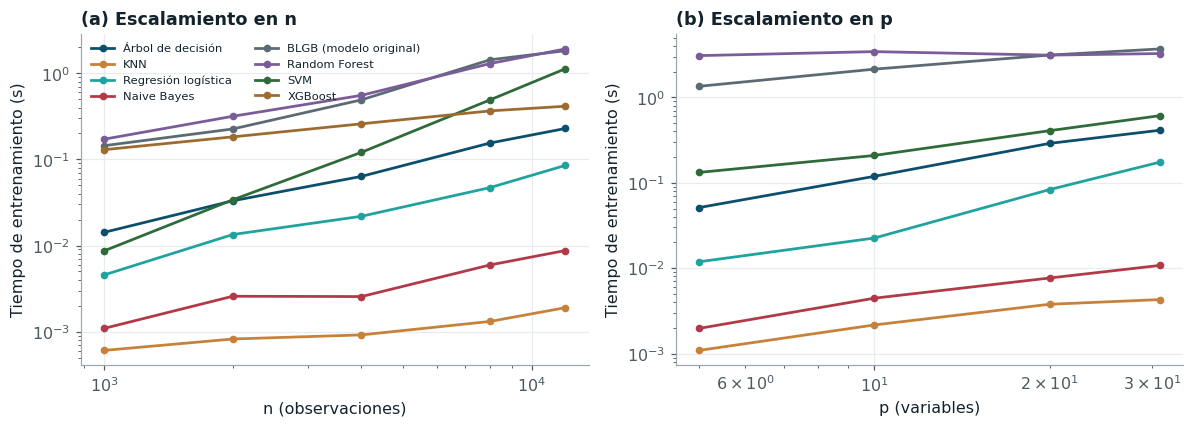

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for i, (m, g) in enumerate(esc[esc.variable == "n"].groupby("modelo")):
    c = (COLORES + ["#7a5c99", "#2f6b3a", "#9c6b30"])[i]
    axs[0].loglog(g.n, g.t_fit, "-o", ms=4, color=c, label=NOMBRES_MODELO.get(m, m))
for i, (m, g) in enumerate(esc[esc.variable == "p"].groupby("modelo")):
    c = (COLORES + ["#7a5c99", "#2f6b3a", "#9c6b30"])[i]
    axs[1].loglog(g.p, g.t_fit, "-o", ms=4, color=c, label=NOMBRES_MODELO.get(m, m))
axs[0].set(xlabel="n (observaciones)", ylabel="Tiempo de entrenamiento (s)", title="(a) Escalamiento en n")
axs[1].set(xlabel="p (variables)", ylabel="Tiempo de entrenamiento (s)", title="(b) Escalamiento en p")
axs[0].legend(fontsize=7.5, ncol=2)
plt.tight_layout(); plt.show()
t = exps.pivot_table(index="modelo", columns="variable", values="exponente_empirico")
t = t.join(exps.drop_duplicates("modelo").set_index("modelo")[["teoria_entrenamiento", "teoria_inferencia"]])
t.index = [NOMBRES_MODELO.get(m, m) for m in t.index]
t = t.rename(columns={"n": "exponente empírico en n", "p": "exponente empírico en p",
                      "teoria_entrenamiento": "O(·) entrenamiento", "teoria_inferencia": "O(·) inferencia"})
for m, v in exps[exps.variable == "n"].set_index("modelo").exponente_empirico.items():
    glue(f"exp_{m}", float(v), display=False)

In [3]:
t.round(2)

,exponente empírico en n,exponente empírico en p,O(·) entrenamiento,O(·) inferencia
Árbol de decisión,1.12,1.17,O(p·n log n),O(profundidad)
KNN,0.43,0.77,O(1) (almacena),O(n·p) por consulta
Regresión logística,1.12,1.51,O(n·p) por iteración,O(p)
Naive Bayes,0.78,0.92,O(n·p),O(p) por consulta
BLGB (modelo original),1.09,NaN,O(T·(n·k + 2^d·k·B)) ×2 ensambles,O(T·d) + O(p log B)
Random Forest,0.98,0.56,O(T·p'·n' log n'),O(T·profundidad)
SVM,1.95,0.01,O(n²·p) a O(n³),O(n_sv·p)
XGBoost,0.48,0.85,O(T·(n·p + 2^d·p·B)) con hist,O(T·d)


Los exponentes empíricos se estimaron con cinco tamaños de muestra entre 1.000 y 12.000 días y
deben leerse como pendientes locales en ese rango, no como órdenes asintóticos. Con esa
salvedad, la concordancia con la teoría es buena en los casos informativos. La SVC con núcleo
RBF escala con un exponente de {glue:text}`exp_svm:.2f`, muy cerca del comportamiento cuadrático
esperado para el problema dual de libsvm, y es la razón por la que en el experimento se usó la
aproximación de Nyström. El árbol de decisión ({glue:text}`exp_arbol:.2f`) y Random Forest
({glue:text}`exp_random_forest:.2f`) siguen el orden $n\log n$ del ordenamiento de los cortes, y
la regresión logística ({glue:text}`exp_logistica:.2f`) el orden lineal por iteración más un
número de iteraciones que crece levemente con n. El modelo original escala con un exponente de
{glue:text}`exp_original:.2f`, lineal como predice la {ref}`proposición 1 <prop-complejidad-ref>`
del capítulo 5. Los exponentes menores que uno de KNN ({glue:text}`exp_knn:.2f`), que en el
entrenamiento solo almacena los datos, y de XGBoost con histogramas ({glue:text}`exp_xgboost:.2f`)
no contradicen la teoría: reflejan costos fijos (validación de datos, construcción de los
histogramas, gestión de hilos) que dominan a tamaños pequeños, de modo que la pendiente en este
rango subestima el orden asintótico.

## Variantes eficientes por modelo

### KNN: estructuras de indexación y vecinos aproximados

In [4]:
knn = pd.read_csv(C / "knn.csv")
base = knn.loc[knn.variante == "sklearn-brute", "t_consulta_ms"].iloc[0]
knn["aceleración vs fuerza bruta"] = base / knn.t_consulta_ms
for v, k in (("faiss-hnsw (aprox.)", "hnsw"), ("sklearn-kd_tree", "kd"), ("faiss-flat (exacto)", "flat")):
    fila = knn[knn.variante == v].iloc[0]
    glue(f"knn_ac_{k}", float(fila["aceleración vs fuerza bruta"]), display=False)
    glue(f"knn_rec_{k}", float(fila.recall_vecinos), display=False)
glue("knn_lento_kd", float(knn.loc[knn.variante == "sklearn-kd_tree", "t_consulta_ms"].iloc[0] / base), display=False)
knn.round(4)

,variante,t_consulta_ms,memoria_pico_mb,pr_auc,recall_vecinos,aceleración vs fuerza bruta
0,sklearn-brute,0.0407,6.2135,0.8890,1.0000,1.0000
1,sklearn-kd_tree,0.4551,6.6873,0.8890,1.0000,0.0895
2,sklearn-ball_tree,0.4249,6.4450,0.8890,1.0000,0.0959
3,faiss-flat (exacto),0.0241,2.6740,0.8890,1.0000,1.6881
4,faiss-hnsw (aprox.),0.0022,8.1945,0.8905,0.9537,18.5706


La búsqueda exhaustiva cuesta $O(np)$ por consulta. Los KD-Trees y Ball Trees reducen ese costo
a $O(\log n)$ cuando la dimensión es baja, pero con 31 variables correlacionadas el número de
ramas que deben visitarse crece y la ventaja desaparece: el KD-Tree resulta más lento que la
fuerza bruta (su tiempo por consulta es {glue:text}`knn_lento_kd:.0f` veces mayor), porque la
búsqueda exhaustiva vectorizada sobre una matriz densa aprovecha mejor la memoria caché que el
recorrido de un árbol que poda poco. FAISS {cite}`johnson2019` con índice plano calcula las mismas
distancias exactas con instrucciones vectorizadas en precisión simple
({glue:text}`knn_ac_flat:.1f` veces), y el grafo HNSW {cite}`malkov2020` encuentra vecinos
aproximados con {glue:text}`knn_ac_hnsw:.1f` veces menos tiempo y recupera el
{glue:text}`knn_rec_hnsw:.1%` de los 30 vecinos exactos. El compromiso entre exactitud y velocidad
es favorable en este problema porque la predicción promedia 30 vecinos: perder algunos y
reemplazarlos por otros casi igual de cercanos apenas cambia la proporción de positivos.

### Ridge y Lasso: solvers

In [5]:
pd.read_csv(C / "lineales.csv").round(4)

,variante,t_fit,rmse_estandarizado_train
0,Ridge auto (Cholesky),0.0058,0.2449
1,Ridge SAGA,2.8221,0.2449
2,Lasso coordenadas,0.5136,0.2514
3,Lasso por SGD (penalización L1),0.0352,0.2523


Con n ≈ 22.000 y p = 31, el solver directo de Ridge (Cholesky sobre la matriz de Gram de
$p\times p$, costo $O(np^2 + p^3)$) es más rápido que SAGA {cite}`defazio2014`, cuyo costo por
época es $O(np)$ pero necesita muchas épocas para converger con variables muy colineales. SAGA
compensa cuando n crece en órdenes de magnitud o los datos son dispersos, condiciones que no se
dan aquí; la decisión de usar el solver por defecto se apoya en esta medición.

### Naive Bayes: aprendizaje incremental

In [6]:
pd.read_csv(C / "naive_bayes.csv").round(5)

,variante,t,memoria_pico_mb,pr_auc,max_dif_vs_completo
0,fit completo,0.00941,7.94649,0.7482,NaN
1,partial_fit lotes de 500,0.01687,0.30553,0.7482,0.0
2,partial_fit lotes de 2000,0.00799,0.82662,0.7482,0.0


`partial_fit` actualiza las medias y varianzas por clase lote a lote con las fórmulas de
actualización de momentos, de modo que el modelo final es el mismo que con `fit` (la diferencia
máxima en las probabilidades es del orden del error de redondeo) y la memoria pico depende del
tamaño del lote y no de n: con lotes de 500 días la memoria pico cae de unos 8 MB a 0,3 MB sin
cambio alguno en las predicciones ni en el tiempo. En este problema todo cabe en memoria y la
ventaja práctica es pequeña; la técnica sería la adecuada si el registro se ampliara a series
subdiarias de toda la red.

### XGBoost: histogramas y parada temprana

In [7]:
xg = pd.read_csv(C / "xgboost.csv")
t_exact = xg.loc[xg.variante == "tree_method=exact", "t_fit"].iloc[0]
t_hist = xg.loc[xg.variante == "tree_method=hist", "t_fit"].iloc[0]
glue("xgb_ac_hist", float(t_exact / t_hist), display=False)
es = xg[xg.variante.str.contains("parada")].iloc[0]
glue("xgb_es_arboles", int(es.n_arboles), display=False)
xg.round(4)

,variante,t_fit,t_inf_ms_fila,memoria_pico_mb,n_arboles,pr_auc
0,tree_method=exact,17.9246,0.0045,0.8056,400,0.9387
1,tree_method=approx,13.7278,0.0048,0.8707,400,0.9357
2,tree_method=hist,1.2826,0.0042,0.8688,400,0.9416
3,hist + parada temprana (validación cronológica...,0.6811,NaN,NaN,86,0.9281
4,hist n_jobs=1,1.2864,NaN,NaN,400,0.9416
5,hist n_jobs=4,0.7754,NaN,NaN,400,0.9416
6,hist n_jobs=10,0.7407,NaN,NaN,400,0.9416


El método exacto ordena cada variable en cada nodo y evalúa todos los cortes posibles; el método
por histogramas discretiza una vez cada variable en un número fijo de bins y acumula gradientes
por bin, lo que reduce el costo por nivel de $O(n\,p\log n)$ a $O(np + p\cdot\text{bins})$. La
aceleración medida es de {glue:text}`xgb_ac_hist:.1f` veces con PR-AUC prácticamente igual. La
parada temprana sobre el último 15 % cronológico del entrenamiento detiene el ajuste en
{glue:text}`xgb_es_arboles` árboles. El modelo original usa la misma idea de histogramas,
programada desde cero.

### SVM: núcleo completo frente a aproximaciones lineales

In [8]:
sv = pd.read_csv(C / "svm.csv")
t_rbf = sv.loc[sv.variante.str.startswith("SVC"), "t_fit"].iloc[0]
sv["aceleración vs SVC"] = t_rbf / sv.t_fit
ny = sv[sv.variante.str.startswith("Nyström")].iloc[0]
glue("ny_ac", float(ny["aceleración vs SVC"]), display=False)
glue("ny_dif", float(ny.pr_auc - sv.loc[sv.variante.str.startswith("SVC"), "pr_auc"].iloc[0]), display=False)
glue("ny_mem", float(ny.memoria_pico_mb), display=False)
sv.round(4)

,variante,t_fit,t_inf_ms_fila,memoria_pico_mb,pr_auc,aceleración vs SVC
0,SVC RBF (libsvm),3.2169,0.2727,6.9116,0.9528,1.0000
1,LinearSVC,0.0861,0.0001,6.0409,0.8889,37.3489
2,SGDClassifier (hinge),0.0450,0.0001,5.8449,0.8736,71.5644
3,Nyström (500) + LinearSVC,1.3089,0.0112,174.8152,0.9429,2.4576


La SVC con núcleo RBF resuelve un problema cuadrático dual cuyo costo crece entre $O(n^2p)$ y
$O(n^3)$, y su inferencia es $O(n_{sv}\,p)$ por consulta. LinearSVC y el descenso de gradiente
estocástico eliminan el núcleo y escalan linealmente, pero pierden la frontera no lineal que el
problema requiere. La aproximación de Nyström {cite}`williams2001` con 500 componentes proyecta los
datos en un espacio de características donde el núcleo es aproximadamente un producto interno, y
recupera la capacidad no lineal con un costo lineal en n: es {glue:text}`ny_ac:.1f` veces más
rápida que la SVC con una diferencia de {glue:text}`ny_dif:+.4f` en PR-AUC, y su inferencia es
un orden de magnitud más rápida porque no depende del número de vectores de soporte. El costo se
traslada a la memoria: la matriz de características de Nyström ($n \times 500$ en doble
precisión) eleva la memoria pico del ajuste de unos 7 MB a {glue:text}`ny_mem:.0f` MB, un
compromiso aceptable en esta máquina pero que habría que vigilar con muestras mucho mayores.

## Paralelización

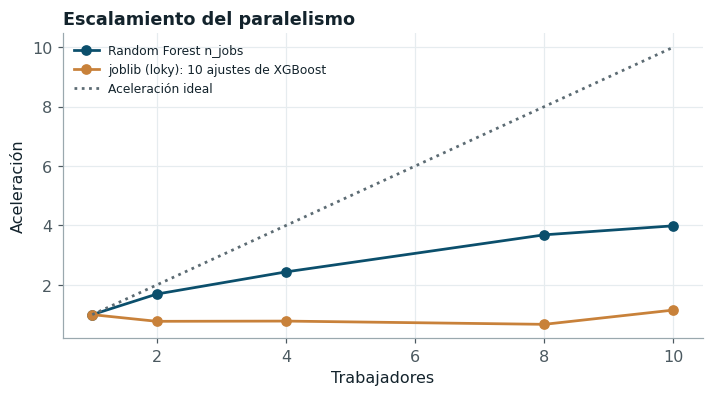

In [9]:
par = pd.read_csv(C / "paralelizacion.csv")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for (esc_, g), c in zip(par.groupby("escenario"), (RIO, SED)):
    ax.plot(g.trabajadores, g.aceleracion, "-o", color=c, label=esc_)
ax.plot([1, 10], [1, 10], ":", color=NEU, label="Aceleración ideal")
ax.set(xlabel="Trabajadores", ylabel="Aceleración", title="Escalamiento del paralelismo"); ax.legend(fontsize=8)
plt.show()
for e, g in par.groupby("escenario"):
    glue("acel_" + ("rf" if "Random" in e else "joblib"), float(g.aceleracion.max()), display=False)
gpu = json.loads((C / "gpu.json").read_text(encoding="utf-8"))
import re
from datetime import datetime
log = (RESULTADOS / "log_cadena.txt").read_text(encoding="utf-8")
t_ini = re.findall(r"== (\d\d:\d\d:\d\d) INICIO clf", log)[-1]; t_fin = re.findall(r"== (\d\d:\d\d:\d\d) INICIO reg", log)[-1]
dur = (datetime.strptime(t_fin, "%H:%M:%S") - datetime.strptime(t_ini, "%H:%M:%S")).seconds / 3600
if dur <= 0: dur += 24
pc = pd.read_parquet(RESULTADOS / "pliegues_clf.parquet")
horas_cpu = (pc.t_opt.sum() + pc.t_fit.sum()) / 3600
glue("horas_tarea", horas_cpu, display=False); glue("horas_reloj", dur, display=False)
glue("concurrencia", horas_cpu / dur, display=False)

El experimento se paralelizó entre tareas y no dentro de ellas: cada tupla (modelo, balanceo,
optimizador, pliegue) es independiente, de modo que diez procesos de `joblib` con el backend
`loky` ejecutan diez optimizaciones a la vez, cada una con estimadores de un solo hilo. Esta
estrategia evita la sobresuscripción (diez procesos con Random Forest de diez hilos competirían
por doce hilos) y resultó eficaz en el experimento real: las 1.344 optimizaciones de
clasificación sumaron {glue:text}`horas_tarea:.1f` horas de tiempo de tarea y se completaron en
{glue:text}`horas_reloj:.1f` horas de reloj, una concurrencia efectiva de
{glue:text}`concurrencia:.1f` procesos simultáneos. La {numref}`fig-paralelo` muestra el
reverso de la medalla: con tareas muy cortas (diez ajustes de XGBoost de menos de medio segundo)
el paralelismo entre procesos no acelera nada, porque el costo de lanzar los procesos y
serializar los datos supera al del cómputo, mientras que el paralelismo interno de Random Forest
alcanza una aceleración de {glue:text}`acel_rf:.1f` con diez hilos. Ninguna curva se acerca a la
ideal porque ocho de los diez núcleos del procesador son de eficiencia, más lentos que los dos de
rendimiento, y la frecuencia baja con la carga sostenida. La lección es que el paralelismo debe
aplicarse al nivel de grano grueso, el de las tareas de minutos, que es como se organizó el
experimento. Con 1.680 optimizaciones y una duración típica de minutos, herramientas distribuidas como Dask o Ray
no se justificaron: el cuello de botella es el número de núcleos, no la coordinación. El equipo
no tiene GPU NVIDIA, de modo que la aceleración con `device='cuda'` de XGBoost no pudo medirse.

## Perfilamiento

In [10]:
perf = pd.read_csv(C / "perfil.csv")
mem = pd.read_csv(C / "memoria.csv"); mem["modelo"] = mem.modelo.map(lambda m: NOMBRES_MODELO.get(m, m))
display(perf.head(12).round(3))
mem.round(2)

,funcion,llamadas,t_propio,t_acumulado
0,experiment.py:ejecutar_tarea,1,0.000,12.935
1,base.py:wrapper,76,0.003,12.486
2,pipeline.py:fit,19,0.001,12.483
3,optim.py:optimizar,1,0.000,12.270
4,optim.py:bayes_search,1,0.000,12.270
5,study.py:optimize,1,0.000,12.269
6,_optimize.py:_optimize,1,0.000,12.269
7,_optimize.py:_optimize_sequential,1,0.001,12.269
8,_optimize.py:_run_trial,6,0.000,12.268
9,optim.py:<lambda>,6,0.000,12.264


,modelo,memoria_pico_fit_mb
0,KNN,6.21
1,Naive Bayes,7.95
2,Regresión logística,6.04
3,Árbol de decisión,3.54
4,Random Forest,4.45
5,XGBoost,0.32
6,SVM,6.91


El perfil de CPU de una tarea elemental (XGBoost con SMOTE y TPE en un pliegue) muestra que cerca
de las tres cuartas partes del tiempo se consumen en la actualización de los árboles de XGBoost
(`core.update`) dentro de la validación interna, mientras que la generación de sintéticos de
SMOTE, la construcción de las matrices de datos y la lógica del optimizador (muestreo de TPE,
registro de Optuna) son marginales. La conclusión práctica fue que la única forma efectiva de acortar el
experimento era reducir el costo de cada ajuste: de ahí la submuestra de 0,3 en Random Forest, la aproximación de Nyström en la SVM, el
método `hist` en XGBoost y el despacho de las tareas más costosas primero para equilibrar la
carga de los procesos.

## Modelo estándar frente a optimizado

In [11]:
filas = [
    ("KNN", "fuerza bruta", "FAISS HNSW", "O(n·p) por consulta", "O(log n) aprox.", knn.loc[knn.variante == "sklearn-brute", "t_consulta_ms"].iloc[0],
     knn.loc[knn.variante == "faiss-hnsw (aprox.)", "t_consulta_ms"].iloc[0], "ms/consulta",
     knn.loc[knn.variante == "faiss-hnsw (aprox.)", "pr_auc"].iloc[0] - knn.loc[knn.variante == "sklearn-brute", "pr_auc"].iloc[0]),
    ("XGBoost", "exact", "hist", "O(n·p log n) por nivel", "O(n·p + p·B) por nivel", t_exact, t_hist, "s (entrenamiento)",
     xg.loc[xg.variante == "tree_method=hist", "pr_auc"].iloc[0] - xg.loc[xg.variante == "tree_method=exact", "pr_auc"].iloc[0]),
    ("SVM", "SVC RBF", "Nyström + LinearSVC", "O(n²·p) a O(n³)", "O(n·m·p)", t_rbf, ny.t_fit, "s (entrenamiento)", ny.pr_auc - sv.loc[sv.variante.str.startswith("SVC"), "pr_auc"].iloc[0]),
]
tabla_so = pd.DataFrame(filas, columns=["Modelo", "Estándar", "Optimizado", "O(·) estándar", "O(·) optimizado", "Tiempo estándar",
                                        "Tiempo optimizado", "Unidad", "Δ PR-AUC"])
mem_std = [knn.loc[knn.variante == "sklearn-brute", "memoria_pico_mb"].iloc[0],
           xg.loc[xg.variante == "tree_method=exact", "memoria_pico_mb"].iloc[0],
           sv.loc[sv.variante.str.startswith("SVC"), "memoria_pico_mb"].iloc[0]]
mem_opt = [knn.loc[knn.variante == "faiss-hnsw (aprox.)", "memoria_pico_mb"].iloc[0],
           xg.loc[xg.variante == "tree_method=hist", "memoria_pico_mb"].iloc[0], ny.memoria_pico_mb]
inf_std = [knn.loc[knn.variante == "sklearn-brute", "t_consulta_ms"].iloc[0],
           xg.loc[xg.variante == "tree_method=exact", "t_inf_ms_fila"].iloc[0], sv.loc[sv.variante.str.startswith("SVC"), "t_inf_ms_fila"].iloc[0]]
inf_opt = [knn.loc[knn.variante == "faiss-hnsw (aprox.)", "t_consulta_ms"].iloc[0],
           xg.loc[xg.variante == "tree_method=hist", "t_inf_ms_fila"].iloc[0], ny.t_inf_ms_fila]
tabla_so.insert(7, "Inferencia estándar (ms/fila)", inf_std); tabla_so.insert(8, "Inferencia optimizada (ms/fila)", inf_opt)
tabla_so["Memoria estándar (MB)"] = mem_std; tabla_so["Memoria optimizada (MB)"] = mem_opt
tabla_so.round(4)

,Modelo,Estándar,Optimizado,O(·) estándar,O(·) optimizado,Tiempo estándar,Tiempo optimizado,Inferencia estándar (ms/fila),Inferencia optimizada (ms/fila),Unidad,Δ PR-AUC,Memoria estándar (MB),Memoria optimizada (MB)
0,KNN,fuerza bruta,FAISS HNSW,O(n·p) por consulta,O(log n) aprox.,0.0407,0.0022,0.0407,0.0022,ms/consulta,0.0014,6.2135,8.1945
1,XGBoost,exact,hist,O(n·p log n) por nivel,O(n·p + p·B) por nivel,17.9246,1.2826,0.0045,0.0042,s (entrenamiento),0.0029,0.8056,0.8688
2,SVM,SVC RBF,Nyström + LinearSVC,O(n²·p) a O(n³),O(n·m·p),3.2169,1.3089,0.2727,0.0112,s (entrenamiento),-0.0099,6.9116,174.8152
